# Exploratory Data Analysis: Student Performance

In this notebook I explore the UCI Student Performance dataset (math class)
to understand the data before building a model.

In [2]:
import sys
print (sys.version)

3.14.6 | packaged by Anaconda, Inc. | (main, Jul  9 2026, 14:29:05) [MSC v.1942 64 bit (AMD64)]


In [3]:
%pip install pandas numpy matplotlib seaborn scikit-learn joblib

Note: you may need to restart the kernel to use updated packages.


In [4]:
#Test the libraries work properly 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
print("All Good!")

All Good!


In [5]:
df = pd.read_csv("../data/student-mat.csv", sep=";")
df

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
390,MS,M,20,U,LE3,A,2,2,services,services,...,5,5,4,4,5,4,11,9,9,9
391,MS,M,17,U,LE3,T,3,1,services,services,...,2,4,5,3,4,2,3,14,16,16
392,MS,M,21,R,GT3,T,1,1,other,other,...,5,5,3,3,3,3,3,10,8,7
393,MS,M,18,R,LE3,T,3,2,services,other,...,4,4,1,3,4,5,0,11,12,10


In [6]:
df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [7]:
#identify the rows and columns

print("Identify the rows and columns: ",df.shape)

Identify the rows and columns:  (395, 33)


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   school      395 non-null    str  
 1   sex         395 non-null    str  
 2   age         395 non-null    int64
 3   address     395 non-null    str  
 4   famsize     395 non-null    str  
 5   Pstatus     395 non-null    str  
 6   Medu        395 non-null    int64
 7   Fedu        395 non-null    int64
 8   Mjob        395 non-null    str  
 9   Fjob        395 non-null    str  
 10  reason      395 non-null    str  
 11  guardian    395 non-null    str  
 12  traveltime  395 non-null    int64
 13  studytime   395 non-null    int64
 14  failures    395 non-null    int64
 15  schoolsup   395 non-null    str  
 16  famsup      395 non-null    str  
 17  paid        395 non-null    str  
 18  activities  395 non-null    str  
 19  nursery     395 non-null    str  
 20  higher      395 non-null    str  
 21  inte

In [9]:
#check missing values
df.isnull().sum()

school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64

In [10]:
#statistical summary
df.describe()

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,2.749367,2.521519,1.448101,2.035443,0.334177,3.944304,3.235443,3.108861,1.481013,2.291139,3.554430,5.708861,10.908861,10.713924,10.415190
std,1.276043,1.094735,1.088201,0.697505,0.839240,0.743651,0.896659,0.998862,1.113278,0.890741,1.287897,1.390303,8.003096,3.319195,3.761505,4.581443
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,16.000000,2.000000,2.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,9.000000,8.000000
50%,17.000000,3.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,11.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,75.000000,19.000000,19.000000,20.000000


## What I found
- The dataset has 395 students and 33 columns.
- There are no missing values.
- The final grade (G3) goes from 0 to 20.
- Some columns are text (like sex, school), so I will need to convert them to numbers later.

In [11]:
df["Pass"] = (df["G3"] >= 10).astype(int)
df["Pass"].value_counts()

Pass
1    265
0    130
Name: count, dtype: int64

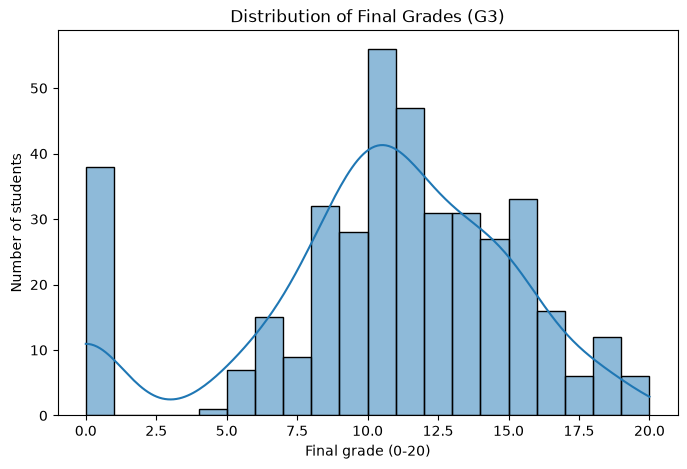

In [12]:
plt.figure(figsize=(8, 5))
sns.histplot(df["G3"], bins=20, kde=True)
plt.title("Distribution of Final Grades (G3)")
plt.xlabel("Final grade (0-20)")
plt.ylabel("Number of students")
plt.show()

**Insight:** Most students scored between 8 and 16, and the most common
grade was around 10 to 11. There is a separate group of about 38 students
with a grade of 0, and almost nobody scored between 1 and 5.

In [14]:
df["pass"] = (df["G3"] >= 10).astype(int)
df["pass"].value_counts()

pass
1    265
0    130
Name: count, dtype: int64

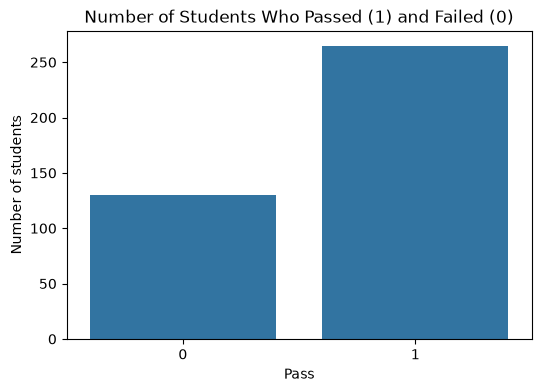

In [16]:
plt.figure(figsize=(6, 4))
sns.countplot(x="pass", data=df)
plt.title("Number of Students Who Passed (1) and Failed (0)")
plt.xlabel("Pass")
plt.ylabel("Number of students")
plt.show()

**Insight:** More students passed than failed (about 265 passed and 130
failed). The two groups are not equal in size. Later, my model should be
better than 67% accuracy, because a model that says "pass" for everyone
would already get 67%.

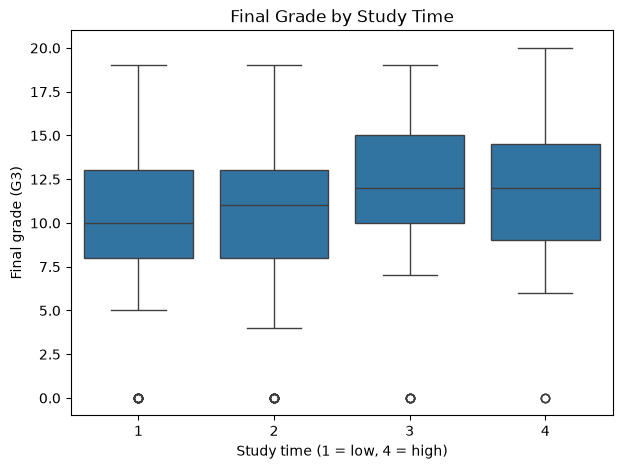

In [18]:
plt.figure(figsize=(7, 5))
sns.boxplot(x="studytime", y="G3", data=df)
plt.title("Final Grade by Study Time")
plt.xlabel("Study time (1 = low, 4 = high)")
plt.ylabel("Final grade (G3)")
plt.show()

**Insight:** Students who study more tend to have slightly higher grades,
but the pattern is weak. The boxes for the different study time groups
overlap a lot, so study time alone does not decide the final grade.

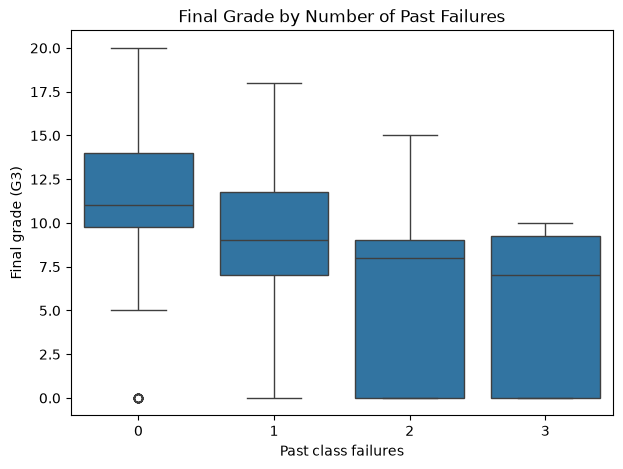

In [19]:
plt.figure(figsize=(7, 5))
sns.boxplot(x="failures", y="G3", data=df)
plt.title("Final Grade by Number of Past Failures")
plt.xlabel("Past class failures")
plt.ylabel("Final grade (G3)")
plt.show()

**Insight:** Students with no past failures have clearly higher final grades
than students with one or more failures. Grades drop as the number of past
failures goes up, so past failures look like an important warning sign.

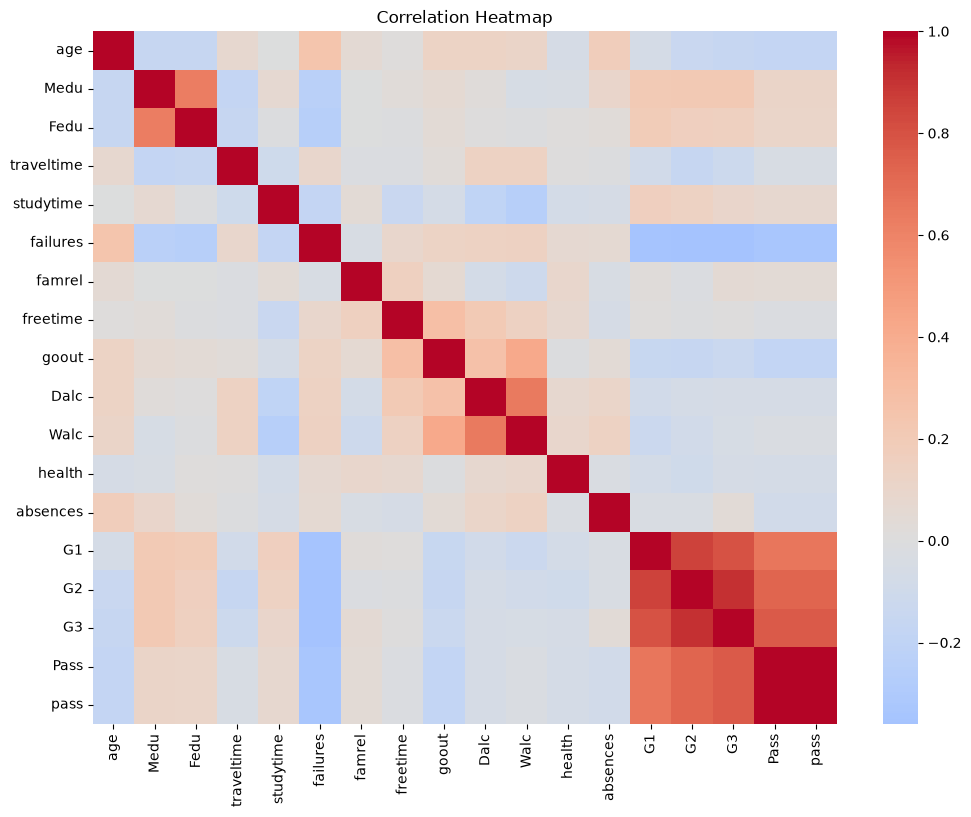

In [20]:
plt.figure(figsize=(12, 9))
corr = df.select_dtypes(include="number").corr()
sns.heatmap(corr, cmap="coolwarm", center=0)
plt.title("Correlation Heatmap")
plt.show()

**Insight:** The grades from earlier in the year (G1 and G2) are very strongly
linked to the final grade G3. Past failures have a negative link, and
mother's education has a small positive link. Surprisingly, absences and
study time have almost no direct link with the final grade.

In [22]:
corr["G3"].sort_values(ascending=False)

G3            1.000000
G2            0.904868
G1            0.801468
Pass          0.770042
pass          0.770042
Medu          0.217147
Fedu          0.152457
studytime     0.097820
famrel        0.051363
absences      0.034247
freetime      0.011307
Walc         -0.051939
Dalc         -0.054660
health       -0.061335
traveltime   -0.117142
goout        -0.132791
age          -0.161579
failures     -0.360415
Name: G3, dtype: float64

**Insight:** Most students scored between 8 and 15. There is a small group
with a grade of 0, which are probably students who did not take the final exam.

## Summary of EDA
- The dataset has 395 students and no missing values.
- About two thirds of students passed, so the two classes are not equal.
- A group of students with a grade of 0 stands out from the rest.
- Past failures are the clearest warning sign for a low grade.
- Study time and absences show only a weak link with the final grade.
- G1 and G2 are very strongly linked to G3, so I will test models with
  and without them.